In [1]:
import sys
sys.path.append('..')

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.data.database import EntityDatabase

from src.data.experiment_data import (
    get_entities_with_complete_data,
    get_entity_summary,
    validate_entity_completeness,
    count_entities_by_culture,
    count_entities_by_country
)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## 1. Connect to Database

In [2]:
db_path = Path('../data/entities.db')
conn = sqlite3.connect(db_path)

print(f"✓ Connected to database: {db_path}")
print(f"  Database size: {db_path.stat().st_size / 1024 / 1024:.2f} MB")

✓ Connected to database: ../data/entities.db
  Database size: 728.42 MB


In [3]:
db = EntityDatabase(db_path)

## 2. Explore Database Contents

In [4]:
# Count total entities
total_entities = pd.read_sql_query('SELECT COUNT(*) as count FROM entities', conn)['count'][0]
print(f"Total entities: {total_entities}")

# Count by entity type
by_type = pd.read_sql_query(
    'SELECT type, COUNT(*) as count FROM entities GROUP BY type',
    conn
)
print("\nEntities by type:")
print(by_type.to_string(index=False))

Total entities: 37254

Entities by type:
  type  count
person  37254


In [5]:
# Count Wikipedia texts by language
wiki_counts = pd.read_sql_query(
    'SELECT language, COUNT(DISTINCT entity_id) as count FROM wikipedia_texts GROUP BY language',
    conn
)
print("Wikipedia texts by language:")
print(wiki_counts.to_string(index=False))

Wikipedia texts by language:
language  count
      ar  35407
      en  35322
      fr  28075


In [6]:
# Count facts by property
fact_counts = pd.read_sql_query(
    '''SELECT f.property, COUNT(DISTINCT f.entity_id) as count
       FROM facts f
       GROUP BY f.property''',
    conn
)
print("Facts by property:")
print(fact_counts.to_string(index=False))

Facts by property:
   property  count
  birthDate  37254
 birthPlace  37254
  deathDate  11258
     gender  37252
nationality  37254
 occupation  37254


## 3. Filter Entities with Complete Data

In [7]:
# Get entities with complete data
languages = ['en', 'fr', 'ar']
entity_type = 'person'
required_facts = ['birthPlace', 'nationality', 'birthDate']

print(f"Filtering entities with:")
print(f"  Languages: {languages}")
print(f"  Entity type: {entity_type}")
print(f"  Required facts: {required_facts}")
print()

complete_entities = get_entities_with_complete_data(
    db,
    languages=languages,
    entity_type=entity_type,
    required_facts=required_facts
)

print(f"\n✓ Found {len(complete_entities)} entities with complete data")

Filtering entities with:
  Languages: ['en', 'fr', 'ar']
  Entity type: person
  Required facts: ['birthPlace', 'nationality', 'birthDate']


✓ Found 26098 entities with complete data


In [8]:
complete_entities[0]

{'id': 1,
 'wikidata_id': 'Q10738',
 'type': 'person',
 'culture': 'Western',
 'country': 'United States',
 'created_at': '2025-12-17 00:26:11',
 'label': 'Dwayne Johnson',
 'labels': {'ar': 'دوين جونسون',
  'en': 'Dwayne Johnson',
  'fr': 'Dwayne Johnson'}}

## 4. Inspect Sample Entities

In [9]:
# Show first 5 entities
print("Sample entities:")
for i, entity in enumerate(complete_entities[:5], 1):
    print(f"\n{i}. {entity['label']} (ID: {entity['id']})")
    print(f"   Wikidata: {entity['wikidata_id']}")
    if 'culture' in entity:
        print(f"   Culture: {entity['culture']}")
    if 'country' in entity:
        print(f"   Country: {entity['country']}")

Sample entities:

1. Dwayne Johnson (ID: 1)
   Wikidata: Q10738
   Culture: Western
   Country: United States

2. Mick Foley (ID: 2)
   Wikidata: Q10731
   Culture: Western
   Country: United States

3. Bill Clinton (ID: 3)
   Wikidata: Q1124
   Culture: Western
   Country: United States

4. Madonna (ID: 4)
   Wikidata: Q1744
   Culture: Western
   Country: United States

5. Jimmy Bennett (ID: 5)
   Wikidata: Q4349
   Culture: Western
   Country: United States


In [10]:
# Get detailed summary of first entity
first_entity_id = complete_entities[0]['id']
summary = get_entity_summary(db, first_entity_id, languages)

print(f"Detailed summary for entity {first_entity_id}:")
print(f"\nLabel: {summary['label']}")
print(f"Type: {summary['entity_type']}")
print(f"Wikidata: {summary['wikidata_id']}")

print(f"\nLabels by language:")
for lang, label in summary['labels'].items():
    print(f"  {lang}: {label}")

print(f"\nFacts:")
for fact in summary['facts']:
    # Show English label if available, otherwise show value
    if 'labels' in fact and 'en' in fact['labels']:
        label = fact['labels']['en']
    else:
        label = fact['value']
    print(f"  {fact['property']}: {label}")

print(f"\nWikipedia texts:")
for wiki in summary['wikipedia_texts']:
    text_preview = wiki['text'][:100] + '...' if len(wiki['text']) > 100 else wiki['text']
    print(f"  {wiki['language']}: {text_preview}")

Detailed summary for entity 1:

Label: Dwayne Johnson
Type: person
Wikidata: Q10738

Labels by language:
  ar: دوين جونسون
  en: Dwayne Johnson
  fr: Dwayne Johnson

Facts:
  birthDate: 1972-05-02T00:00:00Z
  birthPlace: Hayward
  gender: http://www.wikidata.org/entity/Q6581097
  nationality: United States
  occupation: Canadian football player

Wikipedia texts:
  ar: دوين دوغلاس جونسون (بالإنجليزية: Dwayne Douglas Johnson) (من مواليد 2 مايو 1972) والمعروف أيضًا باسم...
  en: Dwayne Douglas Johnson (born May 2, 1972), also known by his ring name "the Rock", is an American ac...
  fr: Dwayne Johnson ([ˈdweɪn ˈd͡ʒɑnsən]) est un acteur, producteur et catcheur (lutteur professionnel) am...


## 5. Analyze Entity Distribution

In [11]:
# Count by culture
culture_counts = count_entities_by_culture(complete_entities)

print("Entities by culture:")
for culture, count in sorted(culture_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {culture}: {count}")

Entities by culture:
  Western: 7007
  Latin American: 5973
  East Asian: 4508
  Arabic: 3836
  African: 2718
  South Asian: 1494
  Southeast Asian: 562


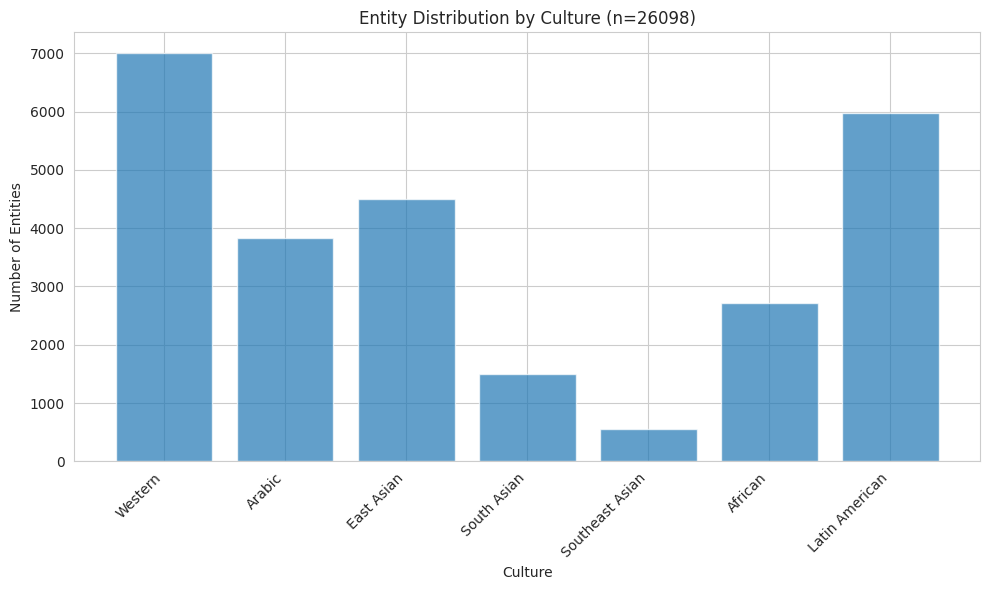

In [12]:
# Visualize culture distribution
fig, ax = plt.subplots(figsize=(10, 6))

cultures = list(culture_counts.keys())
counts = list(culture_counts.values())

ax.bar(range(len(cultures)), counts, alpha=0.7)
ax.set_xticks(range(len(cultures)))
ax.set_xticklabels(cultures, rotation=45, ha='right')
ax.set_xlabel('Culture')
ax.set_ylabel('Number of Entities')
ax.set_title(f'Entity Distribution by Culture (n={len(complete_entities)})')

plt.tight_layout()
plt.show()

In [13]:
# Count by country
country_counts = count_entities_by_country(complete_entities)

print(f"\nEntities by country (top 10):")
for country, count in sorted(country_counts.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"  {country}: {count}")


Entities by country (top 10):
  Brazil: 1908
  Japan: 1789
  United Kingdom: 1777
  France: 1757
  United States: 1756
  Germany: 1717
  Argentina: 1695
  Morocco: 1542
  Mexico: 1424
  South Africa: 1412


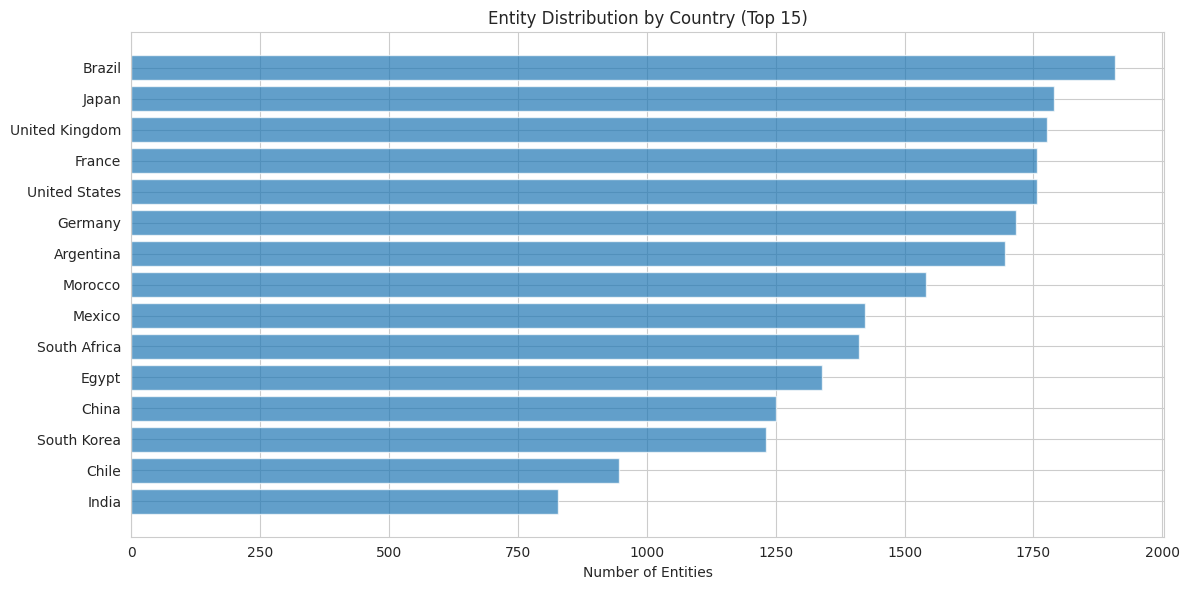

In [14]:
# Visualize top countries
fig, ax = plt.subplots(figsize=(12, 6))

top_countries = sorted(country_counts.items(), key=lambda x: x[1], reverse=True)[:15]
countries = [c[0] for c in top_countries]
counts = [c[1] for c in top_countries]

ax.barh(range(len(countries)), counts, alpha=0.7)
ax.set_yticks(range(len(countries)))
ax.set_yticklabels(countries)
ax.set_xlabel('Number of Entities')
ax.set_title('Entity Distribution by Country (Top 15)')
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## 6. Select Final Entity Set

In [15]:
# Option 1: Use all entities with complete data
selected_entities = complete_entities

# Option 2: Select a subset (e.g., first 50 for initial experiments)
# selected_entities = complete_entities[:50]

# Option 3: Balance by culture
# min_per_culture = 10
# selected_entities = []
# for culture in culture_counts.keys():
#     culture_entities = [e for e in complete_entities if e.get('culture') == culture]
#     selected_entities.extend(culture_entities[:min_per_culture])

print(f"Selected {len(selected_entities)} entities for experiment")

Selected 26098 entities for experiment


## 7. Validate Selected Entities

In [22]:
# Validate a few random entities
import random

sample_ids = random.sample([e['id'] for e in selected_entities], min(5, len(selected_entities)))

print("Validating sample entities:")
for entity_id in sample_ids:
    is_complete, missing = validate_entity_completeness(
        db, entity_id, languages, required_facts
    )

    entity = next(e for e in selected_entities if e['id'] == entity_id)
    status = "✓" if is_complete else "✗"
    print(f"{status} Entity {entity_id} ({entity['label']}): {is_complete}")

    if not is_complete:
        print(f"  Missing: {missing}")

Validating sample entities:
✓ Entity 25791 (Ali Nuhu): True
✓ Entity 29537 (Emil Goeldi): True
✓ Entity 2314 (Robert Delaunay): True
✓ Entity 14344 (Amina Rachid): True
✓ Entity 37188 (Inés Echeverría Bello): True


## 8. Save Entity List

In [23]:
# Save to CSV
output_dir = Path('../data/experiment')
output_dir.mkdir(exist_ok=True)

# Create DataFrame
df = pd.DataFrame(selected_entities)

output_file = output_dir / 'selected_entities.csv'
df.to_csv(output_file, index=False)

print(f"✓ Saved {len(df)} entities to {output_file}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst 3 rows:")
print(df.head(3))

✓ Saved 26098 entities to ../data/experiment/selected_entities.csv

Columns: ['id', 'wikidata_id', 'type', 'culture', 'country', 'created_at', 'label', 'labels']

First 3 rows:
   id wikidata_id    type  culture        country           created_at  \
0   1      Q10738  person  Western  United States  2025-12-17 00:26:11   
1   2      Q10731  person  Western  United States  2025-12-17 00:26:19   
2   3       Q1124  person  Western  United States  2025-12-17 00:26:23   

            label                                             labels  
0  Dwayne Johnson  {'ar': 'دوين جونسون', 'en': 'Dwayne Johnson', ...  
1      Mick Foley  {'ar': 'ميك فولي', 'en': 'Mick Foley', 'fr': '...  
2    Bill Clinton  {'ar': 'بيل كلينتون', 'en': 'Bill Clinton', 'f...  


## 9. Summary Statistics

In [24]:
print("=" * 60)
print("EXPERIMENT DATA SELECTION SUMMARY")
print("=" * 60)
print(f"\nTotal entities selected: {len(selected_entities)}")
print(f"Languages: {languages}")
print(f"Required facts: {required_facts}")

# Recount for selected entities
selected_cultures = count_entities_by_culture(selected_entities)
print(f"\nCulture distribution:")
for culture, count in sorted(selected_cultures.items(), key=lambda x: x[1], reverse=True):
    percentage = (count / len(selected_entities)) * 100
    print(f"  {culture}: {count} ({percentage:.1f}%)")

print(f"\n✓ Ready for embedding generation (notebook 02)")
print("=" * 60)

EXPERIMENT DATA SELECTION SUMMARY

Total entities selected: 26098
Languages: ['en', 'fr', 'ar']
Required facts: ['birthPlace', 'nationality', 'birthDate']

Culture distribution:
  Western: 7007 (26.8%)
  Latin American: 5973 (22.9%)
  East Asian: 4508 (17.3%)
  Arabic: 3836 (14.7%)
  African: 2718 (10.4%)
  South Asian: 1494 (5.7%)
  Southeast Asian: 562 (2.2%)

✓ Ready for embedding generation (notebook 02)


In [25]:
# Close connection
conn.close()
print("Database connection closed")

Database connection closed
